# Three findings

Three datasets, three things that broke, and what each one turned out to be. Nothing here is
retrained from scratch: the notebook imports the same `Experimento` objects that live in
`src/casos/` and stops to look at what they produce.

**The datasets, briefly.** *Quincena* is an invented consumer lender, along with its 2,500
customers and 6,897 loans, put together so there'd be a reproducible test bench; the target is default.
*Olist* is real — a Brazilian marketplace that published a hundred thousand orders in 2018,
and the target is whether an order arrives after the date the customer was promised. *KKBox*
is a music streaming service big in Taiwan; it released twenty-one million subscription
transactions, and the target is churn.

**On naming.** The code and its identifiers are in Spanish, because that's what the module
exports. A short glossary for reading the cells: `entrenar` = train, `abandona` = churned,
`umbral` = threshold, `prueba` = test, `validación` = validation, `abandonos_previos` = prior
churns, `renovaciones_previas` = prior renewals, `revisados` = reviewed, `atrapados` = caught,
`cobertura` = recall.

1. [A probability threshold doesn't hold up over time](#1)
2. [The minimum of the validation curve is noise](#2)
3. [A case that didn't work, and why](#3)

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from casos.kkbox import exp as exp_kkbox
from casos.olist import experimento as exp_olist
from casos.quincena import exp as exp_quincena
from nucleo import construir_tabla, entrenar, tabla_de_umbrales

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)

BLUE, ORANGE, MUTED, AXIS = "#2a78d6", "#eb6834", "#898781", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "font.size": 9, "axes.edgecolor": AXIS, "axes.spines.top": False,
    "axes.spines.right": False, "grid.color": "#e1e0d9", "figure.dpi": 110,
})

<a id="1"></a>
## 1. A probability threshold doesn't hold up over time

Olist again: 96,476 delivered orders, 8.11 % of them late. The model trains on purchases up
to March 2018, gets validated on April and May, and is tested on June to August. Test is
touched once, at the very end.

An AUC of 0.746 comes out of that, which sounds usable. Then you call `predict()` and it
flags almost nothing.

In [2]:
res_olist = entrenar(exp_olist)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in res_olist.metricas.items()})

df = construir_tabla(exp_olist)
m = exp_olist.corte.partir(df)
X = df[exp_olist.columnas_numericas + exp_olist.categoricas]
y = df[exp_olist.objetivo.columna]
p_test = res_olist.pipeline.predict_proba(X[m["pru"]])[:, 1]

print("orders flagged by predict() on test:", int((p_test >= 0.5).sum()), "of", len(p_test))
print("highest probability the model ever predicts:", round(float(p_test.max()), 4))

{'auc': 0.746, 'log_loss': 0.2093, 'n_ent': 64326, 'n_val': 13547, 'n_pru': 18603}


orders flagged by predict() on test: 10 of 18603
highest probability the model ever predicts: 0.6637


Ten out of 18,603.

That isn't the model failing. `predict()` asks "is it more likely than not?", and with 8 % of
orders arriving late the honest answer is almost always no. The model barely ever climbs past
0.5 because it barely ever should.

So the question has to change. The useful one is not "which orders are late" but **"if 10 % of
them can be reviewed, how many does that catch?"** — which is the question an operations team
actually has, because their capacity is fixed.

In [3]:
t_val = tabla_de_umbrales(res_olist.y_val, res_olist.p_val)
t_val.round(3)

,umbral,revisados,atrapados,precision,cobertura,lift
fraccion,,,,,,
0.05,0.225,678,151,0.223,0.165,3.290
0.10,0.185,1355,286,0.211,0.312,3.118
0.15,0.146,2034,373,0.183,0.407,2.709
0.20,0.126,2709,439,0.162,0.479,2.394
0.30,0.099,4064,545,0.134,0.594,1.981


Read the `0.10` row: reviewing the riskiest 10 % catches 31 % of the late deliveries, and
one in five of the orders you look at really is late. The lift column says that's 3.1 times
better than picking orders at random.

That's a usable answer. Now here's where it gets interesting — the thresholds that table
picked on validation, applied unchanged to the test period.

In [4]:
y_test = np.asarray(y[m["pru"]], dtype=float)
rows = []
for f, u in t_val["umbral"].items():
    flagged = p_test >= u
    rows.append({
        "fraction requested": f,
        "threshold": round(float(u), 3),
        "fraction flagged on test": round(float(flagged.mean()), 3),
        "precision": round(float(y_test[flagged].mean()), 3),
    })
pd.DataFrame(rows).set_index("fraction requested")

,threshold,fraction flagged on test,precision
fraction requested,,,
0.05,0.225,0.096,0.185
0.10,0.185,0.161,0.158
0.15,0.146,0.225,0.141
0.20,0.126,0.279,0.124
0.30,0.099,0.376,0.104


Every one flags roughly double what it was set up for. The threshold meant to catch the
top 10 % catches 16 %.

The natural guess is that things got worse — more late orders, so more of them cross the line.
It's the opposite.

In [5]:
print(f"late rate on validation: {res_olist.y_val.mean():.2%}")
print(f"late rate on test      : {y_test.mean():.2%}")

late rate on validation: 6.77%
late rate on test      : 5.48%


Olist got *better* at delivering over those months, from 6.8 % late down to 5.5 %. The model
didn't know that and kept scoring on the scale it learned. Its probabilities drifted upward
while reality improved.

Imagine that threshold frozen in a production system. Three months in, the team is reviewing
60 % more orders than they staffed for, and nothing anywhere threw an error.

The way out is to stop fixing the probability and fix the **capacity** instead. "Review the
top 10 % of today's batch" only depends on the ordering — and the ordering, unlike the
probabilities, holds up.

In [6]:
tabla_de_umbrales(y_test, p_test).round(3)

,umbral,revisados,atrapados,precision,cobertura,lift
fraccion,,,,,,
0.05,0.267,930,191,0.205,0.187,3.749
0.10,0.221,1860,341,0.183,0.335,3.347
0.15,0.191,2801,462,0.165,0.453,3.011
0.20,0.160,3721,541,0.145,0.531,2.654
0.30,0.119,5582,661,0.118,0.649,2.162


Lift of 3.35 at the 10 % mark, slightly better than validation. That rule is written into
the docstring of `tabla_de_umbrales` so the next person doesn't have to rediscover it.

<a id="2"></a>
## 2. The minimum of the validation curve is noise

Switching to Quincena, the synthetic lender, because it trains in seconds and the effect shows
up just as clearly.

Gradient boosting adds trees one at a time, so the usual way to pick how many is to plot the
validation error after each tree and take the lowest point. Let's look at what that lowest
point is actually worth.

In [7]:
res_q = entrenar(exp_quincena)
c = np.asarray(res_q.curva_val)

print(f"exact minimum of the curve : n = {res_q.n_minimo}  (log-loss {c[res_q.n_minimo-1]:.5f})")
print(f"six trees earlier          : n = {res_q.n_minimo-6}  (log-loss {c[res_q.n_minimo-7]:.5f})")
print(f"difference                 : {c[res_q.n_minimo-7] - c[res_q.n_minimo-1]:.5f}")

exact minimum of the curve : n = 173  (log-loss 0.38053)
six trees earlier          : n = 167  (log-loss 0.38070)
difference                 : 0.00017


Seventeen hundred-thousandths apart. The curve reaches bottom and then sits flat for a
hundred trees, and "the minimum" is whichever of those hundred happened to land lowest on this
particular validation set. Pick it and you've fitted noise.

The textbook fix is the one-standard-error rule: keep the smallest model that's within one
standard error of the best. Applied as-is it cut from 173 trees to 29 — and that *did* cost
real performance on test.

The mistake was subtle and worth spelling out. The standard error of the **level** of the loss
answers "how precisely is that 0.3805 known?", and with a thousand validation rows the answer
is: not very. But that is the wrong question. The right one is "how precisely is the gap
between 67 trees and 173 known?", and those two models predict almost identically on the very same
rows. Their errors move together, so the *difference* is pinned down far more tightly than
either number alone.

Same rule, right standard error: the one on the row-by-row difference.

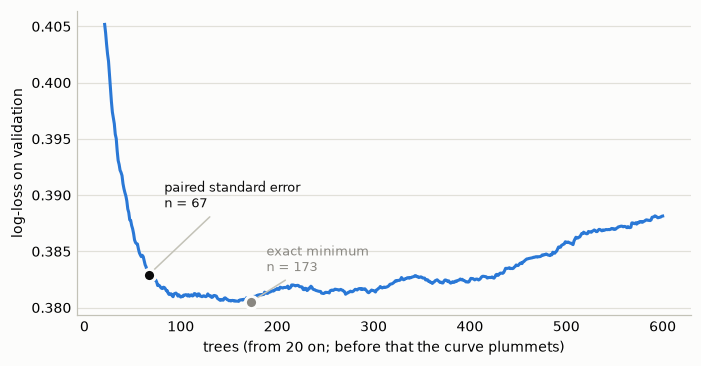

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
n = np.arange(1, len(c) + 1)
ax.plot(n[20:], c[20:], color=BLUE, linewidth=2)
for x, txt, col, dy in [(res_q.n_minimo, f"exact minimum\nn = {res_q.n_minimo}", MUTED, 20),
                        (res_q.mejor_n, f"paired standard error\nn = {res_q.mejor_n}", "#0b0b0b", 44)]:
    ax.plot([x], [c[x-1]], "o", ms=8, color=col, mec="#fcfcfb", mew=2, zorder=5)
    ax.annotate(txt, (x, c[x-1]), textcoords="offset points", xytext=(10, dy),
                fontsize=8.5, color=col, arrowprops=dict(arrowstyle="-", color=AXIS))
ax.set_xlabel("trees (from 20 on; before that the curve plummets)")
ax.set_ylabel("log-loss on validation")
ax.grid(axis="y"); ax.set_axisbelow(True); ax.tick_params(length=0)
plt.show()

173 trees down to 67, and test performance holds. On Olist the same criterion cuts 446 to
266.

One habit that came out of this: if the chosen number lands right at the budget ceiling, it
means nothing at all — you found the edge of `n_max`, not the bottom of the curve. That
happened once on KKBox and the fix was to raise the ceiling, not to trust the number.

<a id="3"></a>
## 3. A case that didn't work, and why

KKBox is where this gets uncomfortable, and it's the part most worth reading.

It joined the project to fill a hole. The two history features — how many prior events this
entity had, and how many went badly — are the most carefully built part of the module, and on
Olist they were worthless, because 96.8 % of those customers buy exactly once. KKBox has a median
of fifteen transactions per user. Finally something to count.

The target: for each transaction, did the user come back within thirty days of their
subscription expiring?

In [9]:
res_k = entrenar(exp_kkbox)
auc_val = roc_auc_score(res_k.y_val, res_k.p_val)
print(f"validation AUC {auc_val:.4f}     test AUC {res_k.metricas['auc']:.4f}")

Binning 0.659 GB of training data: 

0.311 s
Fitting gradient boosted rounds:


Fit 200 trees in 9.394 s, (1595 total leaves)
Time spent computing histograms: 6.217s
Time spent finding best splits:  0.049s
Time spent applying splits:      0.478s
Time spent predicting:           0.226s


Binning 0.659 GB of training data: 

0.302 s
Fitting gradient boosted rounds:


Fit 109 trees in 5.373 s, (872 total leaves)
Time spent computing histograms: 3.432s
Time spent finding best splits:  0.026s
Time spent applying splits:      0.260s
Time spent predicting:           0.117s


validation AUC 0.9101     test AUC 0.5939


0.91 on validation, 0.59 on test. A model that looks excellent until it meets the next
three months.

That gap is too wide for ordinary overfitting. Something is breaking between one period and
the next, and the first suspect is always the feature set — perhaps something got included
that only works in one window. So each variable was checked on its own, quarter by quarter.

In [10]:
df_k = construir_tabla(exp_kkbox)
y_k = df_k[exp_kkbox.objetivo.columna]
quarter = df_k.transaction_date.dt.to_period("Q")
variables = ["plan_list_price", "is_cancel", "abandonos_previos", "dia_semana"]

rows = []
for t in sorted(quarter.unique()):
    sub = quarter == t
    if y_k[sub].nunique() < 2 or sub.sum() < 5000:
        continue
    row = {"quarter": str(t), "churn %": round(y_k[sub].mean() * 100, 2)}
    for cvar in variables:
        s = df_k[cvar][sub]
        row[cvar] = round(roc_auc_score(y_k[sub], s.fillna(s.median())), 3)
    rows.append(row)
by_quarter = pd.DataFrame(rows).set_index("quarter")
by_quarter

,churn %,plan_list_price,is_cancel,abandonos_previos,dia_semana
quarter,,,,,
2015Q1,6.40,0.112,0.531,0.514,0.257
2015Q2,2.01,0.420,0.614,0.552,0.505
2015Q3,2.13,0.546,0.594,0.484,0.361
2015Q4,2.55,0.604,0.686,0.510,0.432
2016Q1,6.23,0.637,0.527,0.489,0.719
2016Q2,1.61,0.681,0.574,0.644,0.504
2016Q3,0.72,0.671,0.641,0.604,0.479
2016Q4,1.60,0.403,0.544,0.493,0.727


An AUC of 0.5 means a variable tells you nothing. Below 0.5 means the relationship runs
backwards — high values now go with *less* churn instead of more.

`plan_list_price` starts at 0.112, which is strongly inverted, climbs all the way to 0.681,
and drops back to 0.403. It flips sides twice. No model can hold a stable rule on top of
that.

And then there's `dia_semana`, the day of the week, sitting at 0.727 in one quarter. There's
no mechanism by which Tuesday makes someone cancel a music subscription. When a variable like
that starts predicting, it isn't finding signal — it's finding an artefact, and it's telling
you the artefact is somewhere in how the data was put together.

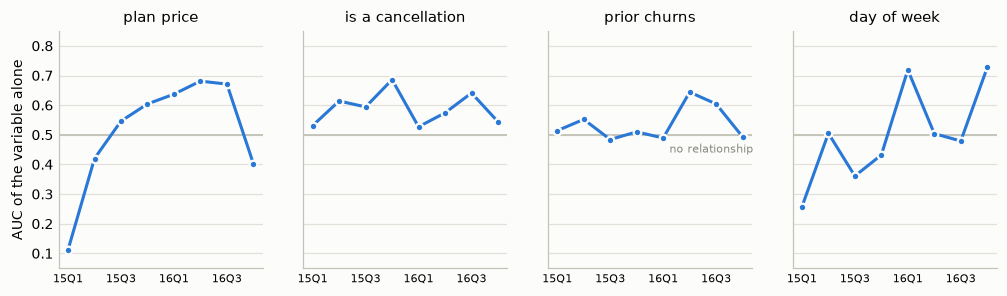

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
x = np.arange(len(by_quarter))
for ax, cvar, title in zip(axes, variables,
                           ["plan price", "is a cancellation",
                            "prior churns", "day of week"]):
    ax.axhline(0.5, color=AXIS, linewidth=1.2)
    ax.plot(x, by_quarter[cvar], color=BLUE, linewidth=2, marker="o", ms=5,
            mec="#fcfcfb", mew=1.5)
    ax.set_title(title, fontsize=9.5)
    ax.set_xticks(x[::2], [s[2:] for s in by_quarter.index[::2]], fontsize=7.5)
    ax.grid(axis="y"); ax.set_axisbelow(True); ax.tick_params(length=0)
axes[0].set_ylabel("AUC of the variable alone"); axes[0].set_ylim(0.05, 0.85)
axes[2].text(len(by_quarter) - 0.6, 0.44, "no relationship", fontsize=7.5,
             color=MUTED, ha="right")
plt.show()

### Where it came from

The problem was in the definition of the target itself, and it took a while to surface.

`abandona` is 1 when no further transaction from that user shows up within thirty days of
expiry. Perfectly sensible sentence. Now apply it to a user with fifteen consecutive
renewals: it's true on exactly one of those fifteen rows — the last one in the file.

So the label isn't really answering "is this person about to leave". It's answering "is this
the last row available for this person", which is a fact about the data window and not about
the person. The model dutifully learned to spot rows near the end of a user's sequence. That
transfers fine within a period that looks similar and falls apart across one that doesn't.

The threshold table shows the damage in its most concrete form.

In [12]:
tabla_de_umbrales(res_k.y_val, res_k.p_val,
                  fracciones=(0.005, 0.01, 0.02, 0.05, 0.10, 0.30)).round(4)

,umbral,revisados,atrapados,precision,cobertura,lift
fraccion,,,,,,
0.005,0.7795,10403,7,0.0007,0.0020,0.0860
0.010,0.7795,10403,7,0.0007,0.0020,0.0860
0.020,0.7795,10403,7,0.0007,0.0020,0.0860
0.050,0.1601,22125,1246,0.0563,0.3615,7.1987
0.100,0.0878,44267,2095,0.0473,0.6078,6.0495
0.300,0.0206,134986,3434,0.0254,0.9962,3.2519


Look at the first three rows: identical, because 10,403 cases share exactly the same
predicted probability. They all fall into one leaf of one tree, and the model announces 78 %
confidence for every one of them. Seven actually churn.

A lift of 0.086 means that group does twelve times *worse* than picking at random. The
model's most confident predictions are its worst ones. Meanwhile at the 5 % mark the lift is
7.2, which is genuinely good.

The ordering is broken at the head and excellent in the middle. An AUC of 0.59 averages those
two facts into a number that describes neither.

---

## What came out of this

The history features worked. They land in the top five by permutation importance on KKBox,
against 1.9 % combined on Olist, so `ConteoPrevio` and `SumaPrevia` do what they were built
to do once there's history to count. The pipeline wasn't the problem.

The problem was the question. KKBox's own competition framed it as one prediction per user at
a single fixed date — everyone whose subscription expired in February 2017 — rather than one
prediction per transaction. That framing removes the artefact completely: if every row sits
at the same point in the calendar, "how far into your sequence are you" stops being a hint.

It's a different problem, and this pipeline is built for events that carry their own date. So
KKBox stays in the repository as a documented limit rather than a fourth result. Given the
choice between a mediocre model presented as a success and a failure explained down to its
cause, the second seems more useful to anyone reading.